In [ ]:
!nvidia-smi

Tue Nov  3 11:57:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:

import numpy as np
import cupy as cp
import time

# Rozmiar macierzy
N = 1024

# CPU
A_cpu = np.random.rand(N, N).astype(np.float32)
B_cpu = np.random.rand(N, N).astype(np.float32)

start_cpu = time.time()
C_cpu = np.matmul(A_cpu, B_cpu)
end_cpu = time.time()

cpu_time = end_cpu - start_cpu

print(f"Czas mnożenia na CPU: {cpu_time:.5f} s")

# GPU
A_gpu = cp.array(A_cpu)
B_gpu = cp.array(B_cpu)

start_gpu = time.time()
C_gpu = cp.matmul(A_gpu, B_gpu)
cp.cuda.Stream.null.synchronize() # Synchronizacja z GPU
end_gpu = time.time()

gpu_time = end_gpu - start_gpu

print(f"Czas mnożenia na GPU: {gpu_time:.5f} s")

# Porownanie
C_gpu_cpu = cp.asnumpy(C_gpu)

print("Czy wyniki są zbliżone:",
      np.allclose(C_cpu, C_gpu_cpu, rtol=1e-3, atol=1e-3))

if gpu_time > 0:
    print(f"Przyspieszenie GPU: {cpu_time / gpu_time:.2f}x")

Czas mnożenia na CPU: 0.01721 s
Czas mnożenia na GPU: 0.00120 s
Czy wyniki są zbliżone: True
Przyspieszenie GPU: 14.39x


In [ ]:
import locale
locale.getpreferredencoding = lambda: "UTF-8"
!pip install pycuda

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 14.5 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for pycuda: filename=pycuda-2026.1-cp313-cp313-linux_x86_64.whl size=5281392 sha256=910a43b13cbf503988ba6112fecf545ae9993d1d723de514a4bf7ab29c545bd9
  Stored in directory: /root/.cache/pip/wheels/ce/26/46/c519675fcb0e5e17bab8e85b6676528c40d12d794182340e85
Successfully built pycuda
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [pycuda]


In [ ]:
import numpy as np
import time
import pycuda.driver as cuda
import pycuda.autoinit
from pycuda.compiler import SourceModule

kernel_code = """
__global__ void matrixMul(float *A, float *B, float *C, int N) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;
    float sum = 0.0;
    if(row < N && col < N) {
        for (int k = 0; k < N; k++) {
            sum += A[row * N + k] * B[k * N + col];
        }
        C[row * N + col] = sum;
    }
}
"""

# Kompilacja kernela
mod = SourceModule(kernel_code)

# Pobranie funkcji CUDA
matrixMul = mod.get_function("matrixMul")

print("Kernel CUDA został skompilowany.")

Kernel CUDA został skompilowany.


In [ ]:

# Rozmiar macierzy
N = 1024

# CPU
A_cpu = np.random.rand(N, N).astype(np.float32)
B_cpu = np.random.rand(N, N).astype(np.float32)

C_cpu = np.empty((N, N), dtype=np.float32)

# GPU
A_gpu = cuda.mem_alloc(A_cpu.nbytes)
B_gpu = cuda.mem_alloc(B_cpu.nbytes)
C_gpu = cuda.mem_alloc(C_cpu.nbytes)

# Przesylanie macierzy wejsciowych na GPU
cuda.memcpy_htod(A_gpu, A_cpu)
cuda.memcpy_htod(B_gpu, B_cpu)

# Konfiguracja blokow i siatki
block_size = (32, 32, 1)
grid_size = (
    (N + block_size[0] - 1) // block_size[0],
    (N + block_size[1] - 1) // block_size[1],
    1
)

# Pomiar czasu
start = time.perf_counter()

matrixMul(
    A_gpu, B_gpu, C_gpu, np.int32(N),
    block=block_size, grid=grid_size
)

cuda.Context.synchronize()
end = time.perf_counter()

gpu_time = end - start

# Pobranie wyniku z GPU
cuda.memcpy_dtoh(C_cpu, C_gpu)

print(f"Rozmiar macierzy: {N} x {N}")
print(f"Czas kernela CUDA: {gpu_time:.5f} s")

# Sprawdzenie poprawnosci
C_reference = np.matmul(A_cpu, B_cpu)

print(
    "Czy wyniki są zbliżone:",
    np.allclose(C_cpu, C_reference, rtol=1e-3, atol=1e-3)
)

# Zwolnienie pamieci GPU
del A_gpu, B_gpu, C_gpu

Rozmiar macierzy: 1024 x 1024
Czas kernela CUDA: 0.00740 s
Czy wyniki są zbliżone: True


In [ ]:
# CPU
start_cpu = time.perf_counter()

C_reference = np.matmul(A_cpu, B_cpu)

cpu_time = time.perf_counter() - start_cpu

print(f"Czas mnożenia na CPU: {cpu_time:.5f} s")
print(f"Czas kernela CUDA: {gpu_time:.5f} s")

if gpu_time > 0:
    print(f"Przyspieszenie CUDA: {cpu_time / gpu_time:.2f}x")

Czas mnożenia na CPU: 0.03925 s
Czas kernela CUDA: 0.00740 s
Przyspieszenie CUDA: 5.31x



Test dla macierzy 128 x 128
NumPy CPU: 0.000050 s
CuPy GPU:  0.000054 s
PyCUDA:    0.000058 s
CuPy poprawny: True
PyCUDA poprawny: True

Test dla macierzy 256 x 256
NumPy CPU: 0.000411 s
CuPy GPU:  0.000102 s
PyCUDA:    0.000156 s
CuPy poprawny: True
PyCUDA poprawny: True

Test dla macierzy 512 x 512
NumPy CPU: 0.002356 s
CuPy GPU:  0.000171 s
PyCUDA:    0.000915 s
CuPy poprawny: True
PyCUDA poprawny: True

Test dla macierzy 1024 x 1024
NumPy CPU: 0.017308 s
CuPy GPU:  0.000888 s
PyCUDA:    0.006773 s
CuPy poprawny: True
PyCUDA poprawny: True


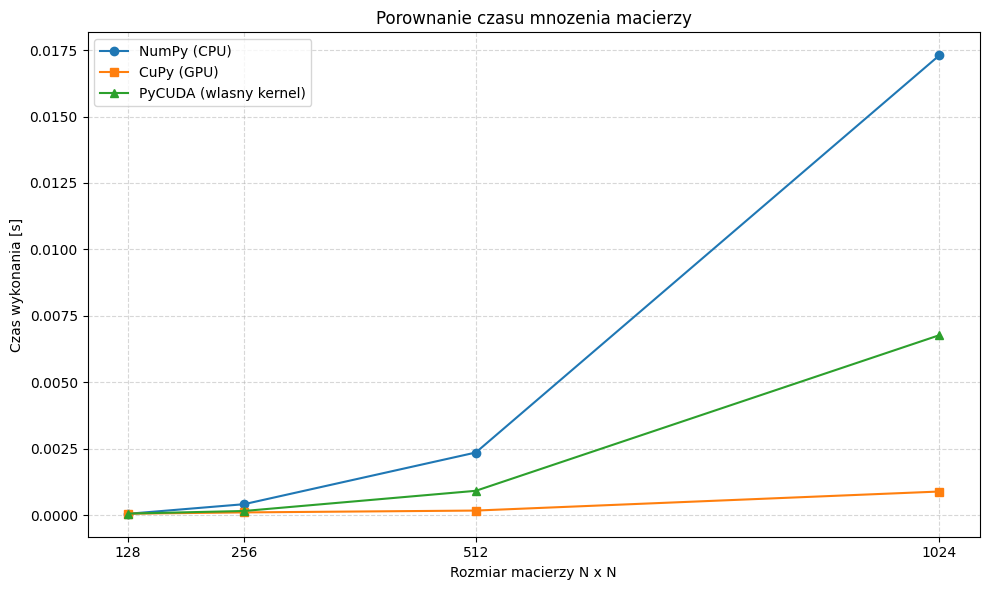

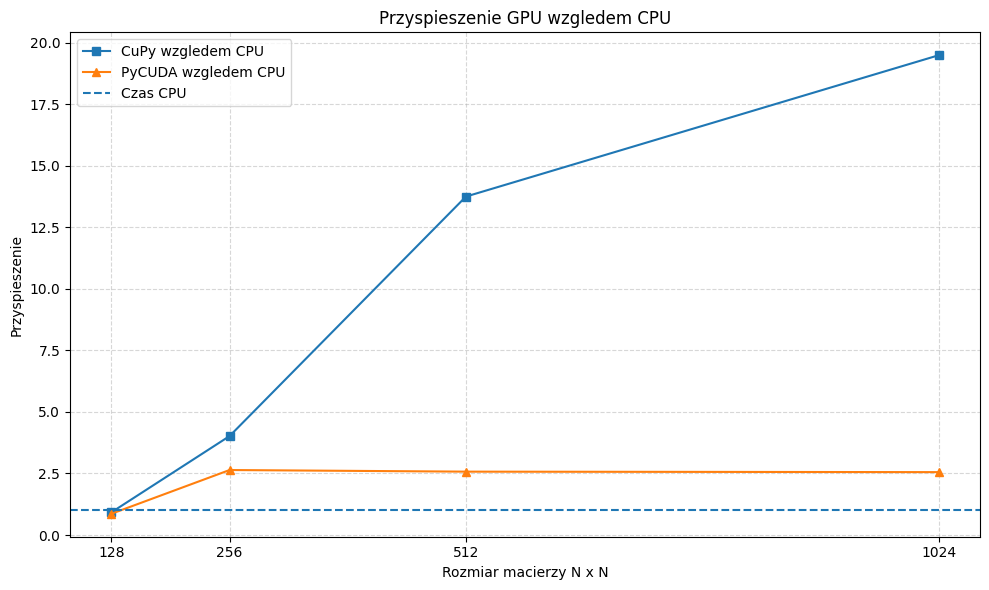

In [ ]:

import numpy as np
import cupy as cp
import pycuda.driver as cuda
import matplotlib.pyplot as plt
import time
from pycuda.compiler import SourceModule

# Rozmiary macierzy
sizes = [128, 256, 512, 1024]

# Wyniki
times_cpu = []
times_cupy = []
times_pycuda = []

# Kernel CUDA
kernel_code = """
__global__ void matrixMul(float *A, float *B, float *C, int N) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;

    float sum = 0.0f;

    if (row < N && col < N) {
        for (int k = 0; k < N; k++) {
            sum += A[row * N + k] * B[k * N + col];
        }
        C[row * N + col] = sum;
    }
}
"""

# Kompilacja kernela
mod = SourceModule(kernel_code)
matrixMul = mod.get_function("matrixMul")

# Konfiguracja PyCUDA
block_size = (32, 32, 1)

# Liczba pomiarow
repeats = 5

for N in sizes:
    print(f"\nTest dla macierzy {N} x {N}")

    # Te same dane dla wszystkich metod
    A = np.random.rand(N, N).astype(np.float32)
    B = np.random.rand(N, N).astype(np.float32)

    # 1. NumPy - CPU
    cpu_measurements = []

    for _ in range(repeats):
        start = time.perf_counter()
        C_cpu = np.matmul(A, B)
        cpu_measurements.append(time.perf_counter() - start)

    cpu_time = np.median(cpu_measurements)
    times_cpu.append(cpu_time)

    # 2. CuPy - GPU
    A_cp = cp.asarray(A)
    B_cp = cp.asarray(B)

    cupy_measurements = []

    for _ in range(repeats):
        cp.cuda.Stream.null.synchronize()
        start = time.perf_counter()

        C_cp = cp.matmul(A_cp, B_cp)
        cp.cuda.Stream.null.synchronize()

        cupy_measurements.append(time.perf_counter() - start)

    cupy_time = np.median(cupy_measurements)
    times_cupy.append(cupy_time)

    # 3. PyCUDA - wlasny kernel
    C = np.empty((N, N), dtype=np.float32)

    A_gpu = cuda.mem_alloc(A.nbytes)
    B_gpu = cuda.mem_alloc(B.nbytes)
    C_gpu = cuda.mem_alloc(C.nbytes)

    cuda.memcpy_htod(A_gpu, A)
    cuda.memcpy_htod(B_gpu, B)

    grid_size = (
        (N + block_size[0] - 1) // block_size[0],
        (N + block_size[1] - 1) // block_size[1],
        1
    )

    pycuda_measurements = []

    for _ in range(repeats):
        start = time.perf_counter()

        matrixMul(
            A_gpu, B_gpu, C_gpu, np.int32(N),
            block=block_size, grid=grid_size
        )
        cuda.Context.synchronize()

        pycuda_measurements.append(time.perf_counter() - start)

    pycuda_time = np.median(pycuda_measurements)
    times_pycuda.append(pycuda_time)

    # Sprawdzenie poprawnosci
    C_cuda = np.empty_like(C)
    cuda.memcpy_dtoh(C_cuda, C_gpu)

    print(f"NumPy CPU: {cpu_time:.6f} s")
    print(f"CuPy GPU:  {cupy_time:.6f} s")
    print(f"PyCUDA:    {pycuda_time:.6f} s")
    print("CuPy poprawny:",
          np.allclose(C_cpu, cp.asnumpy(C_cp),
                      rtol=1e-3, atol=1e-3))
    print("PyCUDA poprawny:",
          np.allclose(C_cpu, C_cuda,
                      rtol=1e-3, atol=1e-3))

    # Zwolnienie pamieci PyCUDA
    del A_gpu, B_gpu, C_gpu

    # Zwolnienie referencji do tablic CuPy
    del A_cp, B_cp, C_cp

# Wykres czasu
plt.figure(figsize=(10, 6))

plt.plot(sizes, times_cpu, marker="o", label="NumPy (CPU)")
plt.plot(sizes, times_cupy, marker="s", label="CuPy (GPU)")
plt.plot(sizes, times_pycuda, marker="^", label="PyCUDA (wlasny kernel)")

plt.xlabel("Rozmiar macierzy N x N")
plt.ylabel("Czas wykonania [s]")
plt.title("Porownanie czasu mnozenia macierzy")
plt.xticks(sizes, [str(n) for n in sizes])
# plt.yscale("log")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# Wykres przyspieszenia
speedup_cupy = np.array(times_cpu) / np.array(times_cupy)
speedup_pycuda = np.array(times_cpu) / np.array(times_pycuda)

plt.figure(figsize=(10, 6))

plt.plot(sizes, speedup_cupy, marker="s", label="CuPy wzgledem CPU")
plt.plot(sizes, speedup_pycuda, marker="^", label="PyCUDA wzgledem CPU")
plt.axhline(y=1, linestyle="--", label="Czas CPU")

plt.xlabel("Rozmiar macierzy N x N")
plt.ylabel("Przyspieszenie")
plt.title("Przyspieszenie GPU wzgledem CPU")
plt.xticks(sizes, [str(n) for n in sizes])
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()